Matplotlib Session 6 – Scatter Plot & Trend Line

USED BIKE DATASET
   age_years  km_driven  price_inr
0          7      26419   63745.35
1          4      53636   65123.62
2         11      53015   21320.84
3          8      57268   55839.43
4          5      21141   70073.92
5          7      83356   77488.76
6         10      74910   24451.44
7          3      59044   82763.10
8          7      70214   55527.13
9         11      36827   29474.25

Dataset Shape: (150, 3)


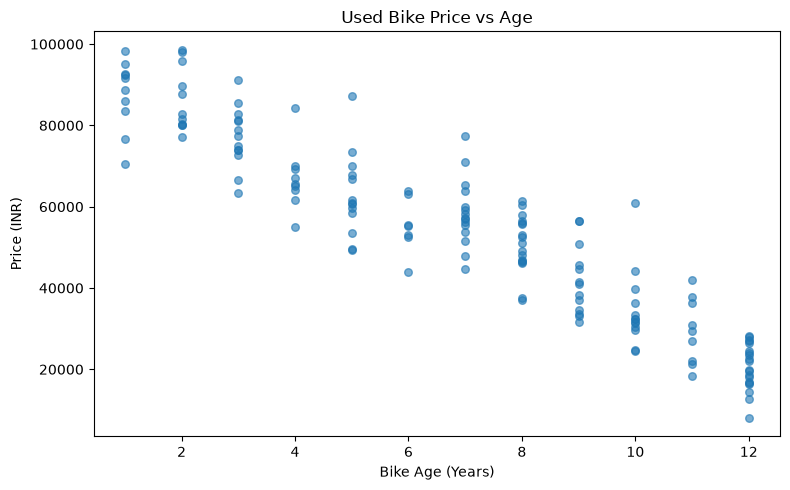

Task 1 completed successfully!
used_bikes.csv created successfully!


In [1]:

# Matplotlib Session 6 - Task 1
# Used Bike Price Analysis

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Set random seed
np.random.seed(42)

# Generate 150 used-bike listings
n = 150

age_years = np.random.randint(1, 13, size=n)

km_driven = np.random.randint(3000, 90001, size=n)

# Calculate bike prices
price_inr = (
    95000
    - 6000 * age_years
    + np.random.normal(0, 8000, size=n)
)

# Minimum price Rs 8,000
price_inr = np.clip(price_inr, 8000, None)

# Create DataFrame
df = pd.DataFrame({
    "age_years": age_years,
    "km_driven": km_driven,
    "price_inr": price_inr.round(2)
})

# Save CSV file
df.to_csv("used_bikes.csv", index=False)

# Display dataset
print("USED BIKE DATASET")
print(df.head(10))

print("\nDataset Shape:", df.shape)

# Create scatter plot
plt.figure(figsize=(8, 5))

plt.scatter(
    df["age_years"],
    df["price_inr"],
    alpha=0.6,
    s=30
)

plt.title("Used Bike Price vs Age")
plt.xlabel("Bike Age (Years)")
plt.ylabel("Price (INR)")

plt.tight_layout()
plt.show()

print("Task 1 completed successfully!")
print("used_bikes.csv created successfully!")


Task 2: Create a Straight Trend Line

Slope: -6034.84
Intercept: 95599.06


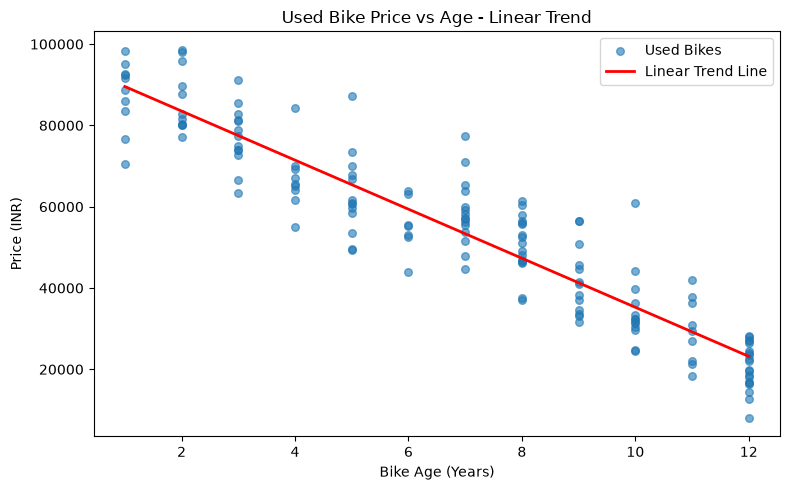

Task 2 completed successfully!
bike_trend_line.png saved successfully!


In [2]:

# Matplotlib Session 6 - Task 2
# Scatter Plot with Linear Regression Trend Line

import numpy as np
import matplotlib.pyplot as plt

# X and Y values
x = df["age_years"]
y = df["price_inr"]

# Fit straight line using np.polyfit()
slope, intercept = np.polyfit(x, y, 1)

# Print slope and intercept
print("Slope:", round(slope, 2))
print("Intercept:", round(intercept, 2))

# Generate 100 evenly spaced X values
x_line = np.linspace(x.min(), x.max(), 100)

# Calculate predicted prices using np.poly1d()
linear_model = np.poly1d([slope, intercept])
y_line = linear_model(x_line)

# Create scatter plot
plt.figure(figsize=(8, 5))

plt.scatter(
    x,
    y,
    alpha=0.6,
    s=30,
    label="Used Bikes"
)

# Draw red trend line
plt.plot(
    x_line,
    y_line,
    color="red",
    linewidth=2,
    label="Linear Trend Line"
)

# Add title and labels
plt.title("Used Bike Price vs Age - Linear Trend")
plt.xlabel("Bike Age (Years)")
plt.ylabel("Price (INR)")
plt.legend()

plt.tight_layout()

# Save BEFORE plt.show()
plt.savefig("bike_trend_line.png")

plt.show()

print("Task 2 completed successfully!")
print("bike_trend_line.png saved successfully!")


Task 3: Compare Linear and Quadratic Regression

Linear R-squared: 0.867
Quadratic R-squared: 0.869
Better Fit: Quadratic Regression


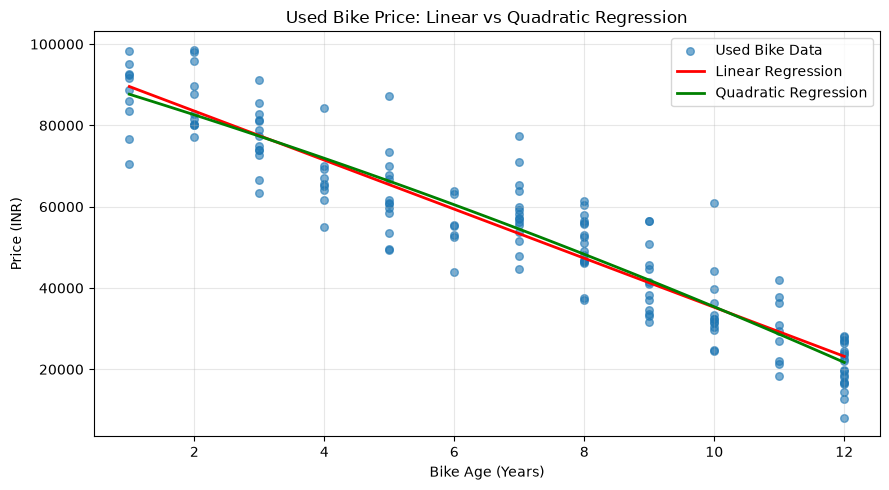

Task 3 completed successfully!
bike_line_vs_curve.png saved successfully!


In [3]:

# Matplotlib Session 6 - Task 3
# Compare Linear and Quadratic Regression

import numpy as np
import matplotlib.pyplot as plt

# Original data
x = df["age_years"].to_numpy()
y = df["price_inr"].to_numpy()

# Fit straight line (degree 1)
linear_coeff = np.polyfit(x, y, 1)
linear_model = np.poly1d(linear_coeff)

# Fit quadratic curve (degree 2)
quadratic_coeff = np.polyfit(x, y, 2)
quadratic_model = np.poly1d(quadratic_coeff)

# Predicted values for original data
y_linear = linear_model(x)
y_quadratic = quadratic_model(x)

# Calculate total sum of squares
SS_tot = np.sum((y - np.mean(y)) ** 2)

# Calculate residual sum of squares
SS_res_linear = np.sum((y - y_linear) ** 2)
SS_res_quadratic = np.sum((y - y_quadratic) ** 2)

# Calculate R-squared
r2_linear = 1 - (SS_res_linear / SS_tot)
r2_quadratic = 1 - (SS_res_quadratic / SS_tot)

print("Linear R-squared:", round(r2_linear, 3))
print("Quadratic R-squared:", round(r2_quadratic, 3))

# Determine better fit
if r2_quadratic > r2_linear:
    better_model = quadratic_model
    print("Better Fit: Quadratic Regression")
else:
    better_model = linear_model
    print("Better Fit: Linear Regression")

# Generate smooth X values
x_line = np.linspace(x.min(), x.max(), 100)

# Create scatter plot
plt.figure(figsize=(9, 5))

plt.scatter(
    x, y,
    alpha=0.6,
    s=30,
    label="Used Bike Data"
)

# Straight regression line
plt.plot(
    x_line,
    linear_model(x_line),
    color="red",
    linewidth=2,
    label="Linear Regression"
)

# Quadratic regression curve
plt.plot(
    x_line,
    quadratic_model(x_line),
    color="green",
    linewidth=2,
    label="Quadratic Regression"
)

plt.title("Used Bike Price: Linear vs Quadratic Regression")
plt.xlabel("Bike Age (Years)")
plt.ylabel("Price (INR)")
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()

# Save BEFORE plt.show()
plt.savefig("bike_line_vs_curve.png")

plt.show()

print("Task 3 completed successfully!")
print("bike_line_vs_curve.png saved successfully!")


Task 4: Predict Bike Price and Create KM Trend Chart

BIKE PRICE PREDICTION
Bike Age: 5 Years
Predicted Price: Rs 66,283.88


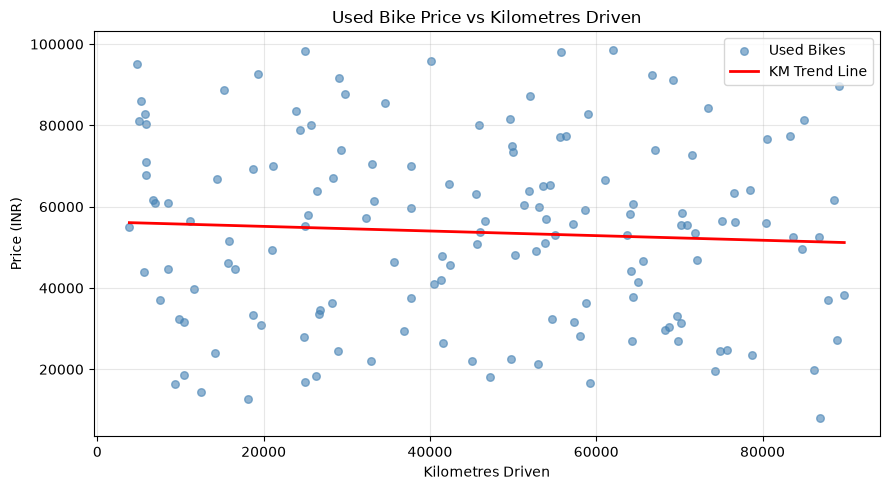

Task 4 completed successfully!
bike_km_trend.png saved successfully!


In [4]:

# Matplotlib Session 6 - Task 4
# Predict Bike Price and Create KM Trend Chart

import numpy as np
import matplotlib.pyplot as plt

# Predict price of a 5-year-old bike
predicted_price = better_model(5)

print("BIKE PRICE PREDICTION")
print("Bike Age: 5 Years")
print(f"Predicted Price: Rs {predicted_price:,.2f}")

# Kilometres driven vs bike price
x_km = df["km_driven"].to_numpy()
y_price = df["price_inr"].to_numpy()

# Fit straight regression line
km_coeff = np.polyfit(x_km, y_price, 1)
km_model = np.poly1d(km_coeff)

# Generate 100 X values
km_line = np.linspace(
    x_km.min(),
    x_km.max(),
    100
)

# Create scatter plot
plt.figure(figsize=(9, 5))

plt.scatter(
    x_km,
    y_price,
    alpha=0.6,
    s=30,
    color="steelblue",
    label="Used Bikes"
)

# Draw trend line
plt.plot(
    km_line,
    km_model(km_line),
    color="red",
    linewidth=2,
    label="KM Trend Line"
)

# Chart formatting
plt.title("Used Bike Price vs Kilometres Driven")
plt.xlabel("Kilometres Driven")
plt.ylabel("Price (INR)")
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()

# Save BEFORE showing
plt.savefig("bike_km_trend.png")

plt.show()

print("Task 4 completed successfully!")
print("bike_km_trend.png saved successfully!")
